# Figure 7a. KNOP1 cis-eQTL and microglial trans-eProgram 27 at an AD locus

Stacked locus plots of the chr16 region (~19.0-20.7 Mb) for AD GWAS (Bellenguez et al.), the astrocyte *KNOP1* *cis*-eQTL and the microglial *trans*-eProgram QTL (Hotspot Program 27). The y-axis is -log10 of the marginal association p-value (two-sided, from z-scores stored in the TransMap/ColocBoost object). Orange points are variants in the ColocBoost colocalization confidence set (CoS) shared by the three traits (robust CoS: p < 1e-4, cos_npc >= 0.5, npc_outcome > 0.2; top variant chr16:19696874:A:G). The gene track (Ensembl GRCh38.103) shows only the genes labelled in the published panel.

Input: `data/Figure_7a_KNOP1_locus.rds`

In [1]:
library(ggplot2)
library(patchwork)
dat <- readRDS("data/Figure_7a_KNOP1_locus.rds")
loc <- dat$locus
head(loc)
## variants per trait and number highlighted in each colocalized set (CoS)
table(loc$trait, ifelse(is.na(loc$cos), "background", loc$cos))
dat$genes[dat$genes$in_figure, ]

,trait,variant,position,neg_log10_p,cos,cos_colour
,<fct>,<chr>,<dbl>,<dbl>,<chr>,<chr>
1,Alzheimer's disease GWAS,chr16:19029859:C:T,19029859,1.2525062,NA,NA
2,Alzheimer's disease GWAS,chr16:19030273:G:A,19030273,1.2678015,NA,NA
3,Alzheimer's disease GWAS,chr16:19030822:C:A,19030822,0.7607873,NA,NA
4,Alzheimer's disease GWAS,chr16:19031962:C:T,19031962,2.6654899,NA,NA
5,Alzheimer's disease GWAS,chr16:19032238:A:G,19032238,0.7817164,NA,NA
6,Alzheimer's disease GWAS,chr16:19033537:A:G,19033537,1.0886900,NA,NA


                                           
                                            background cos2
  Alzheimer's disease GWAS                        2938   62
  Astrocyte KNOP1 cis-eQTL                        2938   62
  Microglia trans-eProgram QTL (Program 27)       2938   62

,gene,chrom,start,end,strand,in_figure,highlight
,<chr>,<chr>,<int>,<int>,<chr>,<lgl>,<lgl>
10,KNOP1,chr16,19701937,19718235,-,TRUE,TRUE
11,IQCK,chr16,19716456,19858467,+,TRUE,FALSE


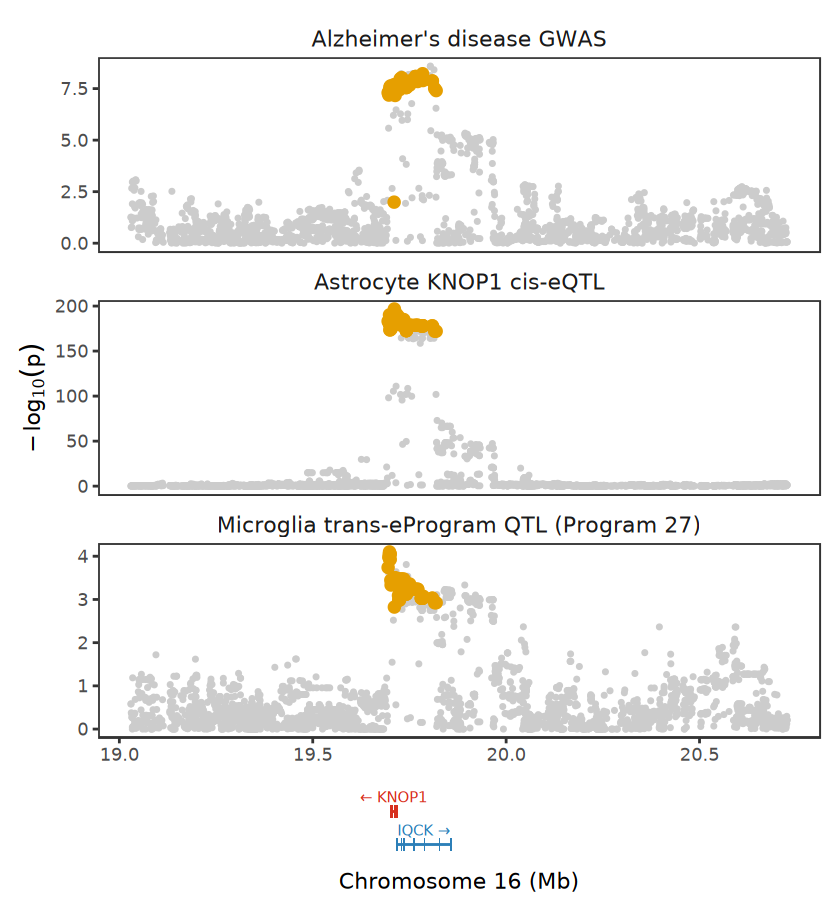

In [2]:

locus_plot <- function(dat, chrom_label, track_height = 1, annot = NULL) {
  loc  <- dat$locus
  xlim <- range(loc$position) / 1e6
  bg <- loc[is.na(loc$cos), ]
  fg <- loc[!is.na(loc$cos), ]
  cos_pal <- unique(fg[, c("cos", "cos_colour")])
  cos_pal <- setNames(cos_pal$cos_colour, cos_pal$cos)

  p_loc <- ggplot() +
    geom_point(data = bg, aes(position / 1e6, neg_log10_p), colour = "grey80", size = 0.8) +
    geom_point(data = fg, aes(position / 1e6, neg_log10_p, colour = cos), size = 2.6) +
    scale_colour_manual(values = cos_pal, guide = "none") +
    facet_wrap(~trait, ncol = 1, scales = "free_y") +
    coord_cartesian(xlim = xlim) +
    labs(x = NULL, y = expression(-log[10](p))) +
    theme_bw(base_size = 13) +
    theme(panel.grid = element_blank(), strip.background = element_blank(),
          strip.text = element_text(size = 13))
  if (!is.null(annot)) p_loc <- p_loc + annot

  ## gene track: only genes drawn in the published panel, packed into rows
  genes <- dat$genes[dat$genes$in_figure, ]
  genes <- genes[order(genes$start), ]
  pad <- diff(xlim) * 1e6 * 0.08
  row_end <- numeric(0); genes$row <- NA
  for (i in seq_len(nrow(genes))) {
    r <- which(row_end < genes$start[i] - pad)[1]
    if (is.na(r)) r <- length(row_end) + 1
    row_end[r] <- genes$end[i]; genes$row[i] <- r
  }
  genes$label <- ifelse(genes$strand == "+", paste0(genes$gene, " →"), paste0("← ", genes$gene))
  exons <- dat$exons[dat$exons$gene %in% genes$gene, ]
  exons$row <- genes$row[match(exons$gene, genes$gene)]
  exons$highlight <- genes$highlight[match(exons$gene, genes$gene)]
  hl <- c(`TRUE` = "#D7301F", `FALSE` = "#2C7FB8")

  p_gene <- ggplot(genes) +
    geom_segment(aes(x = start / 1e6, xend = end / 1e6, y = -row, yend = -row, colour = highlight),
                 linewidth = 0.6) +
    geom_rect(data = exons, aes(xmin = start / 1e6, xmax = end / 1e6, ymin = -row - 0.18,
                                ymax = -row + 0.18, fill = highlight)) +
    geom_text(aes(x = (start + end) / 2e6, y = -row + 0.45, label = label, colour = highlight), size = 3) +
    scale_colour_manual(values = hl, guide = "none") +
    scale_fill_manual(values = hl, guide = "none") +
    scale_y_continuous(expand = expansion(add = c(0.4, 0.7))) +
    coord_cartesian(xlim = xlim) +
    labs(x = chrom_label) +
    theme_void(base_size = 13) +
    theme(axis.title.x = element_text(margin = margin(t = 4)))

  p_loc / p_gene + plot_layout(heights = c(nlevels(loc$trait), track_height))
}

p <- locus_plot(dat, "Chromosome 16 (Mb)", track_height = 0.4)
options(repr.plot.width = 7, repr.plot.height = 7.5)
p